# 06 — The H100's tensor memory accelerator: load latency, issue cost, completion signalling and admission

**Goal.** How long does one asynchronous load through the Tensor Memory Accelerator (TMA) take, from global memory into shared memory, compared with an ordinary load? What does each part of an async copy cost on this H100 NVL:
- issuing the command,
- signalling completion through an mbarrier,
- observing that completion with each of the three wait instructions,
- and moving the payload?

How many copies can one SM keep in flight before issue stalls, how fast does one SM's TMA unit read, and do tensor-map box shapes and descriptor state change the latency?

These numbers set the floor for every TMA-based pipeline on this GPU, and the per-hop decomposition is reused by the later experiments on distributed shared memory, async-proxy bandwidth and collectives.

## Background

**The TMA and the async proxy.** Each SM has one TMA unit, shared by its four sub-partitions.
- **Issue.** A single thread issues a *bulk copy* command. The unit then generates the 32-byte sector requests to the L2 on its own and writes the returned data directly into shared memory: no registers, no L1 lines, no load-store-unit (LSU) instructions per element.
- **Proxies.** These accesses belong to the **async proxy**, a separate path from ordinary (generic-proxy) loads and stores.
- **Commands.** Two kinds exist:
  - *Non-tensor bulk copies* (`cp.async.bulk`) take a global address, a shared-memory address and a size (a multiple of 16 B).
  - *Tensor copies* (`cp.async.bulk.tensor.Nd`) take a 128-byte **tensor map**, built on the host by `cuTensorMapEncodeTiled`, plus integer coordinates. The map describes the tensor: base, sizes and strides of up to 5 dimensions, the box shape, swizzle and L2 promotion. The unit reads the map itself and fetches the box at the given coordinates.
- **The tensor map** is passed as a `__grid_constant__` kernel parameter. The unit caches it, and `prefetch.tensormap` loads it ahead of first use.
- **Swizzling** is a tensor-map option (`NONE`, `32B`, `64B`, `128B`) that changes how the box is laid out in shared memory. Without it, each box row is stored contiguously. With it, the 16-byte pieces of each row are permuted inside a 32/64/128-byte segment by a pattern derived from the row number (an XOR of address bits).
  - **Why.** Shared memory has 32 banks of 4 bytes, and threads of a warp that hit the same bank are served one after another (a *bank conflict*). Reading a column of an unswizzled tile puts all elements in one bank; the permutation spreads a column over all banks. Tensor-core matrix instructions expect operands in these layouts.
  - **Constraints.** A swizzled box row may be at most the swizzle width, and the destination must be aligned to 1024 B for `128B`.

**Completion through an mbarrier.** A bulk load signals completion on an **mbarrier**, a 64-bit object in shared memory.
- **State.** The barrier holds a phase bit, a pending-arrival count and a *transaction count* in bytes.
- **Expecting bytes.** `mbarrier.arrive.expect_tx(bar, B)` counts one arrival and adds *B* expected bytes.
- **Delivering bytes.** When the TMA has written the data, it performs `complete_tx(B)` on the same barrier.
- **Phase completion.** The current phase completes, and the phase bit flips, when both the arrivals and the byte count reach zero. Completion also makes the written data visible to the waiting threads.

A thread observes completion by polling the phase *parity* with one of three instructions:

| PTX | SASS | behaviour |
|---|---|---|
| `mbarrier.test_wait.parity` | `SYNCS.PHASECHK.TRANS64` | non-blocking: returns at once whether the phase has completed |
| `mbarrier.try_wait.parity` | `SYNCS.PHASECHK.TRANS64.TRYWAIT` | potentially blocking: if the phase is incomplete the thread may be suspended until it completes or a system-dependent time limit expires; returns true or false |
| `mbarrier.try_wait.parity …, suspendTimeHint` | `TRYWAIT`, then `NANOSLEEP.SYNCS hint` + `PHASECHK` on a false return | as above, with a requested time limit in ns |

**Issue versus completion.** Issuing a copy means handing the command to the TMA. The issuing warp can continue once the command is accepted, long before the data arrives: the issue cost is the time until the warp can hand over its next command. Completion comes later, when the unit has fetched every byte, written it to shared memory and performed `complete_tx`. A warp can therefore issue many copies before the first one completes.

A **batch** in this experiment is N independent copies issued back to back without waiting in between, all signalling the same mbarrier, which completes when all N copies have arrived. Measuring the time to hand over all N commands (the *issue span*) and the time until all N have arrived, as N grows, exposes:
- the issue cost per command;
- any limit on the number of copies in flight;
- the rate at which the unit moves data.

**Generic twins.** The same dependent chase is also run through three ordinary paths:
- `ld.global.cg`: LSU load that bypasses L1;
- `ld.global.ca`: LSU load that may hit in L1;
- `cp.async.cg`: the Ampere-style asynchronous 16-B copy into shared memory (SASS `LDGSTS`). It goes through the LSU and L1 and completes per thread with `cp.async.wait_group`.

**One hop of the async pointer chase.** The latency kernel follows a random cyclic chain of pointers, one per 128-byte line, as in the generic latency ladder. Each hop is a complete async load whose result supplies the next address:
```cuda
mbarrier.arrive.expect_tx.shared::cta.b64  _, [bar], 16;                          // SYNCS.ARRIVE.TRANS64
cp.async.bulk.shared::cluster.global.mbarrier::complete_tx::bytes [dst], [p], 16, [bar];   // UBLKCP.S.G
wait: mbarrier.try_wait.parity.shared::cta.b64 P, [bar], parity;  @!P bra wait;    // SYNCS.PHASECHK.TRANS64.TRYWAIT
ld.shared.u64 p, [dst];                                                            // LDS: the next pointer
```
A hop therefore contains:
- the expect-tx arrival;
- moving the pointer into uniform registers (`R2UR`), because the TMA takes its operands from the uniform datapath;
- the issue;
- the TMA's L2 round trip and its write into shared memory;
- the completion signal and its observation by the wait;
- one shared-memory load.

A generic hop is a single `LDG`.

## Experimental setup

**Device and fixed configuration.**
- H100 NVL: 132 SMs, 60 MiB L2, HBM3 at 2619 MHz (3.94 TB/s theoretical).
- Power limit 400 W, ECC on, MIG off.
- SM clock locked at 1635 MHz (`nvidia-smi -lgc`); the L2 runs in its own clock domain at ≈ 1556 MHz.
- CUDA 12.9.1; kernels compiled with `nvcc -arch=sm_90a -O3`.
- All latencies are `%clock64` cycles of the SM that runs the timed thread. ns values on secondary axes assume 1635 MHz.

Every launch is followed by an NVML clock and throttle-reason sample, and launches with a throttle reason or a clock below the lock are discarded. The table below gives the measured values.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from common06 import latest_run, read_run, runs

QUICK = False  # True: use the latest --quick smoke-test runs instead of the full runs
R = "results"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.8, "lines.markersize": 4, "legend.frameon": False})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#7a52c7", "#6b6b6b"]  # fixed categorical order
RUN1, RUN2 = latest_run("tma_chase", "chase", QUICK), latest_run("tma_completion", "k2", QUICK)
RUN3, RUN4 = latest_run("tma_issue", "k3", QUICK), latest_run("tma_boxes", "k4", QUICK)
ch = read_run("06__tma__chase.csv", RUN1)
co = read_run("06__tma__completion.csv", RUN2)
iss = read_run("06__tma__issue.csv", RUN3, dtype={"issue_cycles_list": str, "warp_t0_list": str})
bx = read_run("06__tma__boxes.csv", RUN4)
clog = pd.read_csv(f"{R}/06__tma_latency_and_issue__clock_log.csv")
reg = runs()
def latest_ncu(name):
    n = pd.read_csv(f"{R}/06__tma__ncu_{name}.csv")
    full = set(reg[reg.complete & ~reg.cmdline.str.contains("--quick")].run_id) if not QUICK else set(reg.run_id)
    n = n[n.run_id.isin(full)]
    return n[n.run_id == n.run_id.max()].reset_index(drop=True)
nch, nco, nis = latest_ncu("chase"), latest_ncu("completion"), latest_ncu("issue")
gmap = pd.read_csv("../03__sm_gpc_topology/results/03__sm_gpc_topology__map.csv")
gmap = gmap[gmap.run_id == gmap.run_id.max()].set_index("smid").gpc
GPC_PART = {0: 0, 4: 0, 5: 0, 6: 0, 1: 1, 2: 1, 3: 1, 7: 1}
# launches whose clock sample after the launch flagged a throttle reason or a clock below the lock
bad = clog[(clog.phase == "launch") & ((clog.throttle == 1) | (clog.below_lock == 1))][["run_id", "launch_idx"]]
def valid(d):
    k = d.merge(bad.assign(_bad=1), on=["run_id", "launch_idx"], how="left")
    return d[k._bad.isna().values]
disc = {k: len(d) - len(valid(d)) for k, d in [("K1/K5 chase rows", ch), ("K2 rows", co), ("K3 rows", iss), ("K4 rows", bx)]}
ch, co, iss, bx = valid(ch), valid(co), valid(iss), valid(bx)
print("runs used:", {"K1/K5": RUN1, "K2": RUN2, "K3": RUN3, "K4": RUN4, "ncu": nch.run_id[0]})
print("rows of discarded launches (clock below the lock or throttle reason):", disc)

runs used: {'K1/K5': '2026-10-24T17:56:52.147+00:00', 'K2': '2026-10-24T17:37:55.878+00:00', 'K3': '2026-10-24T17:38:07.220+00:00', 'K4': '2026-10-24T17:38:20.328+00:00', 'ncu': '2026-10-24T18:12:51.532+00:00'}
rows of discarded launches (clock below the lock or throttle reason): {'K1/K5 chase rows': 0, 'K2 rows': 0, 'K3 rows': 0, 'K4 rows': 0}


In [2]:
cl = clog[clog.run_id.isin([RUN1, RUN2, RUN3, RUN4])]
L = cl[cl.phase == "launch"]
first = L.iloc[0]
nall = pd.concat([nch, nco, nis])
display(pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "SM clock lock (MHz)": [int(first.lock_sm_mhz)],
    "NVML SM clock after launches (MHz)": [f"{L.sm_clock_mhz.min()}–{L.sm_clock_mhz.max()}"],
    "SM clock under ncu, sm__cycles_elapsed (MHz)": [f"{nall['sm__cycles_elapsed.avg.per_second'].astype(float).median() / 1e6:.0f}"],
    "L2 clock under ncu, lts__cycles_elapsed (MHz)": [f"{nall['lts__cycles_elapsed.avg.per_second'].astype(float).median() / 1e6:.0f}"],
    "memory clock (MHz)": [f"{L.mem_clock_mhz.min()}–{L.mem_clock_mhz.max()}"],
    "power (W)": [f"{L.power_w.min():.0f}–{L.power_w.max():.0f}"],
    "GPU / HBM temperature (°C)": [f"≤ {L.gpu_temp_c.max()} / ≤ {L.mem_temp_c.max()}"],
    "recorded launches (K1/K2/K3/K4)": ["/".join(str(cl[(cl.run_id == r) & (cl.phase == 'launch')].shape[0]) for r in [RUN1, RUN2, RUN3, RUN4])],
    "launches with a throttle reason or below the lock": [int(((L.throttle == 1) | (L.below_lock == 1)).sum())],
}).T.rename(columns={0: ""}))
print("probe SMs of K1:", sorted(ch.smid.unique()), "→ GPCs", [int(gmap[s]) for s in sorted(ch.smid.unique())],
      "| K2 SM:", sorted(co[co.kind == "copy"].smid.unique()), "| K4 SM:", sorted(bx.smid.dropna().unique().astype(int)))

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
SM clock lock (MHz),1635
NVML SM clock after launches (MHz),1635–1635
"SM clock under ncu, sm__cycles_elapsed (MHz)",1630
"L2 clock under ncu, lts__cycles_elapsed (MHz)",1555
memory clock (MHz),2619–2619
power (W),87–99


probe SMs of K1: [np.int64(2), np.int64(8)] → GPCs [1, 4] | K2 SM: [np.int64(2)] | K4 SM: [np.int64(124)]


**What each kernel measures.**

| | kernel | timed region | placement and cache state | sweep, repetitions |
|---|---|---|---|---|
| K1 | async pointer chase: 16-B bulk copy per hop. Variants:<br>• tensor 1-D (box 2 × 8 B)<br>• tensor 2-D (4×4 floats = 64 B, rows of 16 B, so still one 128-B line per hop)<br>• `.L2::cache_hint` evict_last<br>• `cp.async.bulk.prefetch.L2` of the line two hops ahead (each line also stores that address)<br>• `try_wait` with suspend hints 0/100/1000 ns<br>• a `test_wait` loop | `%clock64` around ≥ 2^16 dependent hops (16 inlined per loop iteration). Start and end timestamps wait for the previous hop's value, so they bracket complete hops | One thread on a chosen SM: the first SM of GPC 1 and of GPC 4, one in each L2 partition. ≤ 128 MiB: an in-kernel warm pass over the whole chain first, then ≥ one full cycle timed. Above: 2^19 timed hops of a cold chain, with the L2 cleaned (flushed, then refilled with other clean data) before every launch | 72 footprints, 1 KiB – 2 GiB (×1.25 steps), 5 launches each |
| K5 | the same chain with `ld.global.cg`, `ld.global.ca` and `cp.async.cg` 16 B + `wait_group 0` | same | same | same |
| K2 | one bulk copy of P bytes from global memory into shared memory | `expect_tx` before t0; t0 → issue → t_issue → wait loop → t1, where t1 is read after the loop's final branch. The timer floor (2 cycles) is subtracted | Pinned to the first SM of GPC 1.<br>• L2 source: a 4 MiB buffer warmed by the same SM.<br>• HBM source: L2 flushed, never-touched lines.<br>Consecutive samples start in different 4-KiB pages, so the L2 slices vary | `try_wait`: 399 payloads 16 B – 64 KiB. Other wait forms and the HBM source: 19 payloads. 5 launches × 32 samples each |
| K2 | predicate kernels: 1024 dependent wait calls on a completed phase, minus an identical chain without the wait; calls on a never-completing phase; 1024 `arrive.expect_tx` calls, dependent or back to back | `%clock64` around the chain | one thread | 5 launches each |
| K3 | batches of N independent bulk copies (distinct destinations, one barrier expecting N × size), fully unrolled and issued by lane 0 of 1, 2 or 4 warps | `%clock64` after every issue (one `CS2R` each), and when the phase completes | 1 CTA per SM (200 KiB of shared memory). 1, 2, 4 or 8 SMs start each sample at the same `%globaltimer` instant. L2 source (warm 4 MiB) or HBM source (L2 flushed before each launch) | N = 1–32 (4 KiB and 1 KiB copies); N = 1–64 (2 KiB, 4 warps). 5 launches × 16 samples |
| K4 | one 16-KiB 3-D tensor load (float tensor 1024 × 256 × 256), 5 box shapes, swizzle none/128B | as K2. Coordinates are in registers before t0 | One thread, 160 KiB destination. Four identical tensor maps let a descriptor be used for the first time at a chosen point of the launch. L2 warm or HBM cold data. Half the launches shift every load to the other barrier parity | 20 launches × 19 timed loads |

**Repetitions and discarded data.**
- No launch was discarded: every clock sample after a launch showed 1635 MHz with no throttle reason.
- A first complete K1 run did not clean the L2 between the launches above 128 MiB. Its five launches revisited the same 2^19 lines (64 MiB), so part of them were L2 hits, and the "HBM" plateau came out ≈ 55 cycles too low. That run is superseded by the run shown here, which differs only by the cleaning step.
- Smoke-test runs with reduced sweeps exist in the raw data and are not used.

## Results

### 1. Latency of one dependent async load versus footprint (K1, K5)

**Figure 1.** Cycles per dependent hop versus footprint for the three TMA forms (solid) and the three generic twins (dashed). Lines are medians over the 5 launches of both probe SMs, with p5–p95 bands. The lower panel gives the difference to `ld.global.cg` on the same chain.

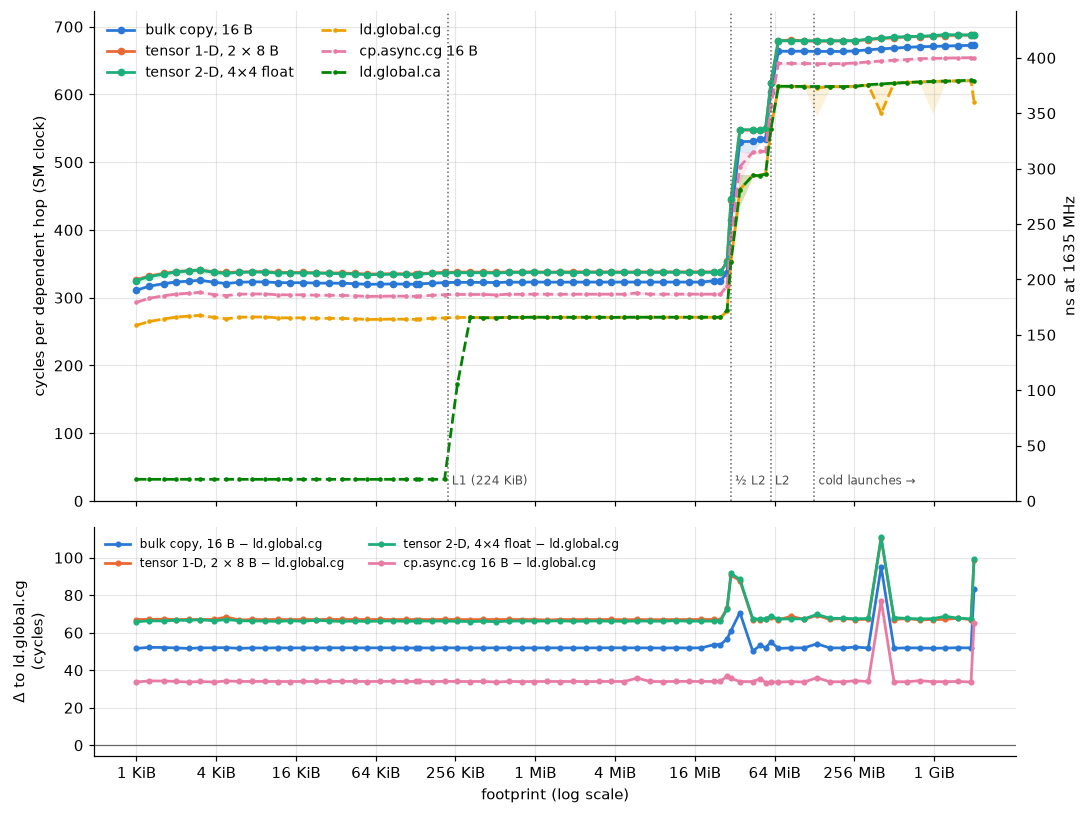

In [3]:
TMA = [("bulk16", "bulk copy, 16 B"), ("tensor1d", "tensor 1-D, 2 × 8 B"), ("tensor2d", "tensor 2-D, 4×4 float")]
GEN = [("ld_cg", "ld.global.cg"), ("cp_async16", "cp.async.cg 16 B"), ("ld_ca", "ld.global.ca")]
med = ch.groupby(["variant", "footprint_bytes"]).cycles_per_hop.median().unstack(0)
p5 = ch.groupby(["variant", "footprint_bytes"]).cycles_per_hop.quantile(0.05).unstack(0)
p95 = ch.groupby(["variant", "footprint_bytes"]).cycles_per_hop.quantile(0.95).unstack(0)
x = med.index / 2**20
fig, (ax, bx2) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.4]})
for j, (v, lab) in enumerate(TMA + GEN):
    if v not in med: continue
    ax.fill_between(x, p5[v], p95[v], color=C[j], alpha=0.15, lw=0)
    ax.plot(x, med[v], color=C[j], marker="o" if j < 3 else ".", ls="-" if j < 3 else "--", label=lab)
for f, t in [(0.21875, "L1 (224 KiB)"), (30, "½ L2"), (60, "L2"), (128, "cold launches →")]:
    ax.axvline(f, color="0.4", ls=":", lw=1); ax.text(f, 20, " " + t, fontsize=8, color="0.3", va="bottom")
ax.set_xscale("log", base=2); ax.set_ylim(0, None); ax.set_ylabel("cycles per dependent hop (SM clock)")
sec = ax.secondary_yaxis("right", functions=(lambda c: c / 1.635, lambda n: n * 1.635)); sec.set_ylabel("ns at 1635 MHz")
ax.legend(ncol=2, fontsize=9, loc="upper left")
for j, (v, lab) in enumerate(TMA + [("cp_async16", "cp.async.cg 16 B")]):
    if v in med: bx2.plot(x, med[v] - med["ld_cg"], color=C[j if j < 3 else 4], marker="o", ms=3, label=lab + " − ld.global.cg")
bx2.axhline(0, color="0.4", lw=0.8); bx2.set_ylabel("Δ to ld.global.cg\n(cycles)"); bx2.legend(fontsize=8, ncol=2)
bx2.set_xlabel("footprint (log scale)")
ticks = [2**k for k in range(-10, 12, 2)]
def size_label(mib):
    return f"{mib * 1024:g} KiB" if mib < 1 else (f"{mib:g} MiB" if mib < 1024 else f"{mib / 1024:g} GiB")
bx2.set_xticks(ticks, [size_label(t) for t in ticks])
fig.tight_layout(); plt.show()

- **All three TMA forms track the generic L2 load at a constant offset over the whole range.**
  - The bulk copy needs ≈ 323 cycles per hop while the data is in L2, against 271 for `ld.global.cg`: **+52 cycles**.
  - In HBM (≥ 512 MiB, cold) it needs ≈ 671 against 618: again **+52**.
  - The tensor forms add ≈ 15 cycles more (+67).
  - `cp.async.cg` sits in between (+35).
- **The TMA never hits in L1.** `ld.global.ca` runs at 32 cycles up to the 224 KiB of L1, while every async form already pays the full L2 latency at 1 KiB.
- **The L2 capacity region is shifted equally for all forms:**
  - the single-SM near plateau ends at ≈ 29 MiB;
  - an intermediate plateau follows at 40–50 MiB;
  - HBM latency is reached by ≈ 64 MiB.

**Plateaus** (median and p5–p95 over all launches of both SMs inside each footprint range). *Poll floor* is the latency of the variant's wait instruction on an already completed barrier (section 2); it is part of every TMA hop. The second table gives TMA − generic, the third the two probe SMs separately.

In [4]:
REG = {"L1-size (16–128 KiB)": (16 << 10, 128 << 10), "L2 (1–16 MiB)": (1 << 20, 16 << 20), "HBM (≥ 512 MiB)": (512 << 20, 4 << 30)}
rows = {}
for v in ["bulk16", "tensor1d", "tensor2d", "bulk16_evict_last", "bulk16_prefetch", "bulk16_hint0", "bulk16_hint100",
          "bulk16_hint1000", "bulk16_testwait", "cp_async16", "ld_cg", "ld_ca"]:
    d = ch[ch.variant == v]
    r = {}
    for name, (lo, hi) in REG.items():
        s = d[(d.footprint_bytes >= lo) & (d.footprint_bytes <= hi)].cycles_per_hop
        r[name] = f"{s.median():.1f} ({s.quantile(.05):.1f}–{s.quantile(.95):.1f})"
    pf = d.poll_floor_cycles.dropna()
    r["poll floor"] = f"{pf.iloc[0]:.1f}" if len(pf) else "—"
    rows[v] = r
t1 = pd.DataFrame(rows).T
display(t1)
def reg_med(v, name):
    lo, hi = REG[name]; d = ch[(ch.variant == v) & (ch.footprint_bytes >= lo) & (ch.footprint_bytes <= hi)]
    return d.cycles_per_hop.median()
delta = pd.DataFrame({name: {v: reg_med(v, name) - reg_med("ld_cg", name) for v in ["bulk16", "tensor1d", "tensor2d", "cp_async16"]}
                      for name in ["L2 (1–16 MiB)", "HBM (≥ 512 MiB)"]}).round(1)
delta.index = [f"{v} − ld_cg" for v in delta.index]
display(delta)
per_sm = ch[ch.variant.isin(["bulk16", "ld_cg"])].assign(region=lambda d: np.where(d.footprint_bytes <= 16 << 20, "≤ 16 MiB", "≥ 512 MiB"))
per_sm = per_sm[(per_sm.footprint_bytes >= 1 << 20) & ((per_sm.footprint_bytes <= 16 << 20) | (per_sm.footprint_bytes >= 512 << 20))]
display(per_sm.groupby(["variant", "region", "smid"]).cycles_per_hop.median().unstack("smid").round(1).rename(columns=lambda s: f"SM {s} (G{gmap[s]})"))

,L1-size (16–128 KiB),L2 (1–16 MiB),HBM (≥ 512 MiB),poll floor
bulk16,321.4 (318.3–323.1),323.1 (320.9–324.9),670.9 (667.7–674.7),29.5
tensor1d,336.6 (333.5–338.3),338.2 (335.9–340.0),686.3 (682.8–689.7),29.5
tensor2d,335.1 (333.2–337.0),337.5 (335.5–338.7),686.6 (684.2–689.6),29.5
bulk16_evict_last,322.4 (319.4–324.3),324.1 (321.8–325.9),672.4 (668.6–675.7),29.5
bulk16_prefetch,324.4 (321.4–326.2),326.1 (323.8–327.9),513.4 (510.5–516.4),29.5
bulk16_hint0,321.3 (318.3–323.2),323.1 (320.8–324.9),627.3 (622.4–672.9),59.6
bulk16_hint100,321.4 (318.4–323.2),323.1 (320.8–324.9),628.7 (622.4–674.7),59.6
bulk16_hint1000,321.4 (318.3–323.2),323.1 (320.8–324.9),667.9 (623.7–674.8),59.6
bulk16_testwait,340.1 (337.8–341.4),341.5 (339.3–343.3),687.1 (641.5–692.2),29.5
cp_async16,303.5 (300.4–305.3),306.8 (303.3–307.0),652.9 (649.6–656.6),—


,L2 (1–16 MiB),HBM (≥ 512 MiB)
bulk16 − ld_cg,51.9,52.6
tensor1d − ld_cg,67.0,68.0
tensor2d − ld_cg,66.3,68.3
cp_async16 − ld_cg,35.6,34.6


smid               SM 2 (G1)  SM 8 (G4)
variant region                         
bulk16  ≤ 16 MiB       324.9      321.4
        ≥ 512 MiB      674.0      669.0
ld_cg   ≤ 16 MiB       273.0      269.5
        ≥ 512 MiB      621.5      617.2

**Figure 1b.** Effect of the cache hint, the speculative L2 prefetch and the wait instruction, as cycles per hop relative to the plain `bulk16` chase on the same chain.

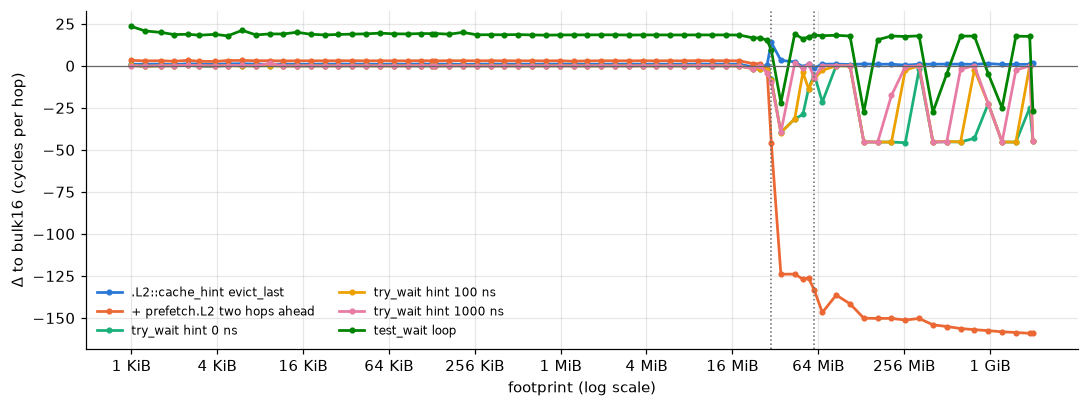

In [5]:
VAR = [("bulk16_evict_last", ".L2::cache_hint evict_last"), ("bulk16_prefetch", "+ prefetch.L2 two hops ahead"),
       ("bulk16_hint0", "try_wait hint 0 ns"), ("bulk16_hint100", "try_wait hint 100 ns"), ("bulk16_hint1000", "try_wait hint 1000 ns"),
       ("bulk16_testwait", "test_wait loop")]
fig, ax = plt.subplots(figsize=(10, 3.8))
for j, (v, lab) in enumerate(VAR):
    if v in med: ax.plot(x, med[v] - med["bulk16"], color=C[j], marker="o", ms=3, label=lab)
ax.axhline(0, color="0.4", lw=0.8)
for f in [30, 60]: ax.axvline(f, color="0.4", ls=":", lw=1)
ax.set_xscale("log", base=2); ax.set_xticks(ticks, [size_label(t) for t in ticks]); ax.set_xlabel("footprint (log scale)")
ax.set_ylabel("Δ to bulk16 (cycles per hop)"); ax.legend(fontsize=8, ncol=2); fig.tight_layout(); plt.show()

- **Prefetch.** A `cp.async.bulk.prefetch.L2` of the line two hops ahead hides ≈ 125 cycles per hop at 40–64 MiB and 150–160 cycles in HBM (513 instead of 671 at ≥ 512 MiB). The prefetch is issued one hop, ≈ 670 cycles, before the line is needed, so part of the HBM access still shows.
- **evict_last** has no measurable effect on a single-SM chase.
- **test_wait.** While the data is in L2, a `test_wait` loop costs +18 cycles per hop: it observes the completion up to one poll later (one call + branch ≈ 50 cycles, see section 2).
- **Hint forms.** The suspend-hint forms cost nothing extra at L2 latency.
- **Two modes in HBM.** For long waits (HBM), the hint forms and `test_wait` run in one of two states:
  - either equal to the plain forms (`try_wait`: 671 cycles; `test_wait`: +18),
  - or **≈ 45 cycles per hop faster** (hints ≈ 625, i.e. faster than the plain `try_wait`).

  The state holds for several consecutive launches and then switches; it does not depend on the SM or the footprint. The plain `try_wait` loop was never in the fast state.

### 2. Polling, signalling and completion of one copy (K2)

**Predicate and arrival costs.** Cycles per call in a dependent chain. "glue" is the `selp` + `mad` that turns each predicate into the next address. Subtracting a chain in which a `setp` replaces the wait leaves the wait's own latency, minus the few cycles of the replaced `setp`.

In [6]:
P = co[co.kind.isin(["pred", "pred_baseline", "pred_incomplete"])]
pm = P.groupby(["wait_variant", "kind"]).cycles_predicate_only.median().unstack()
pt = pd.DataFrame({"call on a completed phase, chain incl. glue": pm["pred"], "glue chain (setp + selp + mad)": pm["pred_baseline"],
                   "wait call − glue": pm["pred"] - pm["pred_baseline"],
                   "call on an incomplete phase (returns false)": pm["pred_incomplete"]}).loc[["try", "test", "hint0", "hint100", "hint1000"]]
pt["… in µs at 1635 MHz"] = pt["call on an incomplete phase (returns false)"] / 1635
display(pt.round(2))
E = co[co.kind.isin(["expect_tx_lat", "expect_tx_issue"])].groupby("kind").cycles_predicate_only.describe()[["count", "min", "50%", "max"]]
display(E.rename(index={"expect_tx_lat": "arrive.expect_tx, dependent (latency)", "expect_tx_issue": "arrive.expect_tx, independent (issue)"}).round(2))
tf = co[co.kind == "timer_floor"].cycles_issue_to_complete
print(f"timer floor (clock64 → clock64): median {tf.median():.0f}, min {tf.min():.0f}, max {tf.max():.0f} cycles")

,"call on a completed phase, chain incl. glue",glue chain (setp + selp + mad),wait call − glue,call on an incomplete phase (returns false),… in µs at 1635 MHz
wait_variant,,,,,
try,44.01,14.48,29.53,7766.07,4.75
test,43.95,14.48,29.47,44.16,0.03
hint0,74.05,14.48,59.57,7873.39,4.82
hint100,74.05,14.48,59.57,7874.73,4.82
hint1000,74.05,14.48,59.57,7874.73,4.82


,count,min,50%,max
kind,,,,
"arrive.expect_tx, independent (issue)",5.0,8.02,8.02,8.02
"arrive.expect_tx, dependent (latency)",5.0,39.70,39.70,39.71


timer floor (clock64 → clock64): median 2, min 2, max 2 cycles


- **Wait instructions.** On a completed phase, `try_wait` and `test_wait` both return their predicate in ≈ 30 cycles (44 with the chain glue). With a suspend hint the same call costs ≈ 60.
- **`try_wait` on an incomplete phase** returns false only after **≈ 7770 cycles (4.75 µs)**. With a hint it takes ≈ 4.8 µs whatever the hint (0, 100 or 1000 ns): ptxas emits a plain `TRYWAIT` first and uses the hint only in the `NANOSLEEP.SYNCS` of the retry path. A `try_wait` loop therefore normally needs exactly one call, while `test_wait` returns at once and is re-polled.
- **`arrive.expect_tx`** issues every 8 cycles back to back. Its returned state is available after ≈ 40 cycles, including the `mad` of the chain.

**Figure 2.** Issue → observed completion of one bulk copy, timer floor subtracted.
- Left: the full payload range. Fine sweep with the `try_wait` loop from L2 (median, p5–p95 band), coarse sweeps for the other wait forms, and HBM-sourced copies with p5–p95 error bars. The dotted line is the linear fit over payloads ≥ 8 KiB.
- Right: zoom on 16 B – 8 KiB.

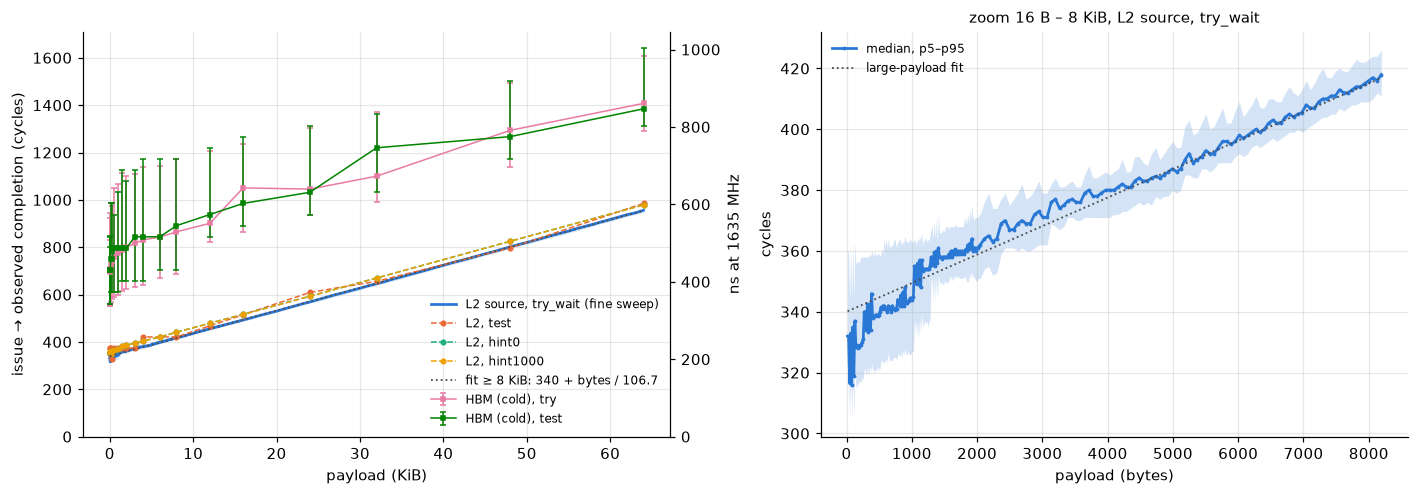

fit over payloads ≥ 8 KiB: T0 = 340.0 cycles, 106.7 B/cycle per SM (174 GB/s at 1635 MHz); 16-B copy: 332 cycles (timer floor 2 subtracted)


In [7]:
cp = co[co.kind == "copy"]
TF = tf.median()
L2T = cp[(cp.source == "l2") & (cp.wait_variant == "try")]
g = L2T.groupby("payload_bytes").cycles_issue_to_complete
m2, q5, q95 = g.median() - TF, g.quantile(.05) - TF, g.quantile(.95) - TF
fit_mask = m2.index >= 8192
A = np.vstack([np.ones(fit_mask.sum()), m2.index[fit_mask]]).T
(T0, slope), *_ = np.linalg.lstsq(A, m2.values[fit_mask], rcond=None)
BW = 1 / slope
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
ax.fill_between(m2.index / 1024, q5, q95, color=C[0], alpha=0.2, lw=0)
ax.plot(m2.index / 1024, m2.values, color=C[0], label="L2 source, try_wait (fine sweep)")
for j, w in enumerate(["test", "hint0", "hint1000"]):
    h = cp[(cp.source == "l2") & (cp.wait_variant == w)].groupby("payload_bytes").cycles_issue_to_complete.median() - TF
    ax.plot(h.index / 1024, h.values, color=C[j + 1], marker="o", ms=3, ls="--", lw=1, label=f"L2, {w}")
for j, w in enumerate(["try", "test"]):
    h = cp[(cp.source == "hbm") & (cp.wait_variant == w)].groupby("payload_bytes").cycles_issue_to_complete
    hm = h.median() - TF
    ax.errorbar(hm.index / 1024, hm.values, yerr=[hm - (h.quantile(.05) - TF), (h.quantile(.95) - TF) - hm], color=C[4 + j], marker="s", ms=3,
                capsize=2, lw=1, label=f"HBM (cold), {w}")
xx = np.array([0, 64]); ax.plot(xx, T0 + xx * 1024 / BW, color="0.3", ls=":", lw=1.2, label=f"fit ≥ 8 KiB: {T0:.0f} + bytes / {BW:.1f}")
ax.set_xlabel("payload (KiB)"); ax.set_ylabel("issue → observed completion (cycles)"); ax.legend(fontsize=8); ax.set_ylim(0, None)
sec = ax.secondary_yaxis("right", functions=(lambda c: c / 1.635, lambda n: n * 1.635)); sec.set_ylabel("ns at 1635 MHz")
ax = axs[1]
z = m2[m2.index <= 8192]
ax.fill_between(z.index, q5[z.index], q95[z.index], color=C[0], alpha=0.2, lw=0)
ax.plot(z.index, z.values, color=C[0], marker=".", ms=3, label="median, p5–p95")
ax.plot(z.index, T0 + z.index / BW, color="0.3", ls=":", lw=1.2, label="large-payload fit")
ax.set_xlabel("payload (bytes)"); ax.set_ylabel("cycles"); ax.set_title("zoom 16 B – 8 KiB, L2 source, try_wait", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
print(f"fit over payloads ≥ 8 KiB: T0 = {T0:.1f} cycles, {BW:.1f} B/cycle per SM "
      f"({BW * 1.635:.0f} GB/s at 1635 MHz); 16-B copy: {m2.iloc[0]:.0f} cycles (timer floor {TF:.0f} subtracted)")

**Small-payload structure.** Median jumps between neighbouring payloads, local slopes, and the number of wait calls until the predicate became true.

In [8]:
# step structure of the small-payload region: first differences of the medians (16-B steps up to 2 KiB, 64-B steps above)
zz = m2[m2.index <= 16384]
dz = zz.diff()
steps = dz[dz > 6]
print("payloads where the median jumps by > 6 cycles relative to the previous payload:")
display(pd.DataFrame({"jump (cycles)": steps.round(1), "previous payload": [zz.index[zz.index.get_loc(p) - 1] for p in steps.index]}).T)
for lo, hi in [(16, 512), (512, 2048), (2048, 8192), (8192, 65536)]:
    s = m2[(m2.index >= lo) & (m2.index <= hi)]
    b = np.polyfit(s.index, s.values, 1)
    print(f"  {lo:>5}–{hi:<5} B: slope {b[0]:.4f} cycles/B (= {1 / b[0] if b[0] > 0 else float('inf'):.1f} B/cycle), intercept {b[1]:.1f}")
pol = cp[(cp.source == "l2")].groupby(["wait_variant", "payload_bytes"]).polls.median().unstack(0)
display(pol.loc[[p for p in [16, 1024, 4096, 16384, 65536] if p in pol.index]].T.rename(columns=lambda p: f"{p} B").astype(int)
        .rename_axis("wait calls until true (median)"))

payloads where the median jumps by > 6 cycles relative to the previous payload:


payload_bytes,64,96,128,272,320,352,384,1040,1088,1120,1152
jump (cycles),16.5,19.0,18.0,9.0,8.5,9.0,12.0,10.0,7.0,8.0,9.0
previous payload,48.0,80.0,112.0,256.0,304.0,336.0,368.0,1024.0,1072.0,1104.0,1136.0


     16–512   B: slope 0.0331 cycles/B (= 30.2 B/cycle), intercept 324.9
    512–2048  B: slope 0.0163 cycles/B (= 61.2 B/cycle), intercept 331.8
   2048–8192  B: slope 0.0087 cycles/B (= 115.3 B/cycle), intercept 345.3
   8192–65536 B: slope 0.0094 cycles/B (= 106.7 B/cycle), intercept 340.0


payload_bytes,16 B,1024 B,4096 B,16384 B,65536 B
wait calls until true (median),,,,,
hint0,1,1,1,1,1
hint100,1,1,1,1,1
hint1000,1,1,1,1,1
test,6,6,7,9,19
try,1,1,1,1,1


- **Small copies.** One 16-B copy from L2 completes ≈ 330 cycles after its issue (p5–p95 ≈ 320–360, depending on the L2 slice that holds the line). From HBM (cold) the median is ≈ 705 cycles, with a wide spread (≈ 550–940) set by the HBM access.
- **Up to 1 KiB the time is almost flat** (330–347 cycles), with a 15–20-cycle zigzag between neighbouring 16-B sizes below 128 B. A step of ≈ +10 cycles follows just above 1 KiB.
- **Above ≈ 2 KiB the completion time grows linearly.** The fit over 8–64 KiB gives **T0 ≈ 340 cycles + bytes / 107 B/cycle** (174 GB/s per SM at 1635 MHz). That is 83 % of the 128 B/cycle that Nsight Compute reports as the rated TMA read peak per SM (section 5).
- **Polls.** A single copy therefore never keeps the read path busy for less than its fixed latency. The `try_wait` loop always needed one call. The `test_wait` loop needed 6 calls for small copies and 19 for 64 KiB, i.e. one call every ≈ 50 cycles.

**Figure 2b.** Distribution of the completion time of a 4-KiB copy for each wait form (L2 and HBM sources), and the median of each form minus `try_wait`, per source and payload.

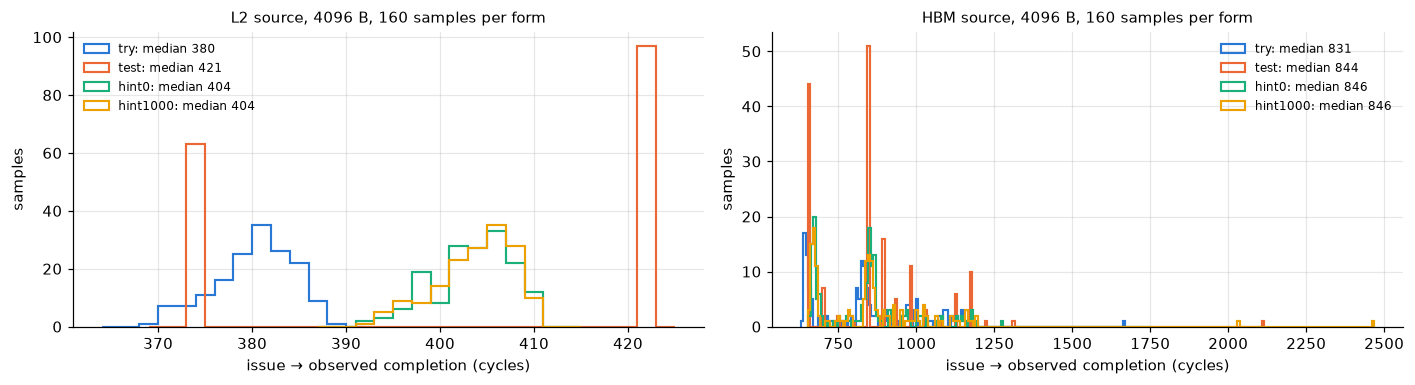

median − try_wait (cycles)  test  hint0  hint100  hint1000
source payload_bytes                                      
hbm    16                   -2.5   18.5     22.0      27.0
       1024                 22.0   20.5      2.5      13.5
       4096                 13.0   15.0     27.5      14.5
       16384               -65.5  -16.5    -36.0      28.5
       65536               -23.0  -11.0    -15.0      12.5
l2     16                   42.0   24.0     23.5      24.5
       1024                 29.0   24.5     24.0      24.0
       4096                 41.0   24.0     24.0      24.0
       16384                22.0   24.0     23.0      23.0
       65536                29.0   23.0     23.0      22.5

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (src, P0) in zip(axs, [("l2", 4096), ("hbm", 4096)]):
    for j, w in enumerate(["try", "test", "hint0", "hint1000"]):
        h = cp[(cp.source == src) & (cp.wait_variant == w) & (cp.payload_bytes == P0)].cycles_issue_to_complete - TF
        ax.hist(h, bins=np.arange(h.min() - 5, h.max() + 6, 2 if src == "l2" else 8), histtype="step", color=C[j], lw=1.4,
                label=f"{w}: median {h.median():.0f}")
    ax.set_title(f"{src.upper()} source, {P0} B, {int((cp.source == src).sum() and len(h))} samples per form", fontsize=10)
    ax.set_xlabel("issue → observed completion (cycles)"); ax.set_ylabel("samples"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
cmp = cp.groupby(["source", "payload_bytes", "wait_variant"]).cycles_issue_to_complete.median().unstack()
display((cmp[["test", "hint0", "hint100", "hint1000"]].sub(cmp["try"], axis=0)).loc[pd.IndexSlice[:, [16, 1024, 4096, 16384, 65536]], :]
        .round(1).rename_axis(columns="median − try_wait (cycles)"))

### 3. Issue cost, admission and per-SM throughput (K3)

**Figure 3.** Left: issue span, from the first issue to the return of the last, versus the number of copies N. Right: time until all N copies have completed (median and p5–p95). Solid lines are the L2 source, dashed lines HBM. Dotted verticals at N = 16 and 32.

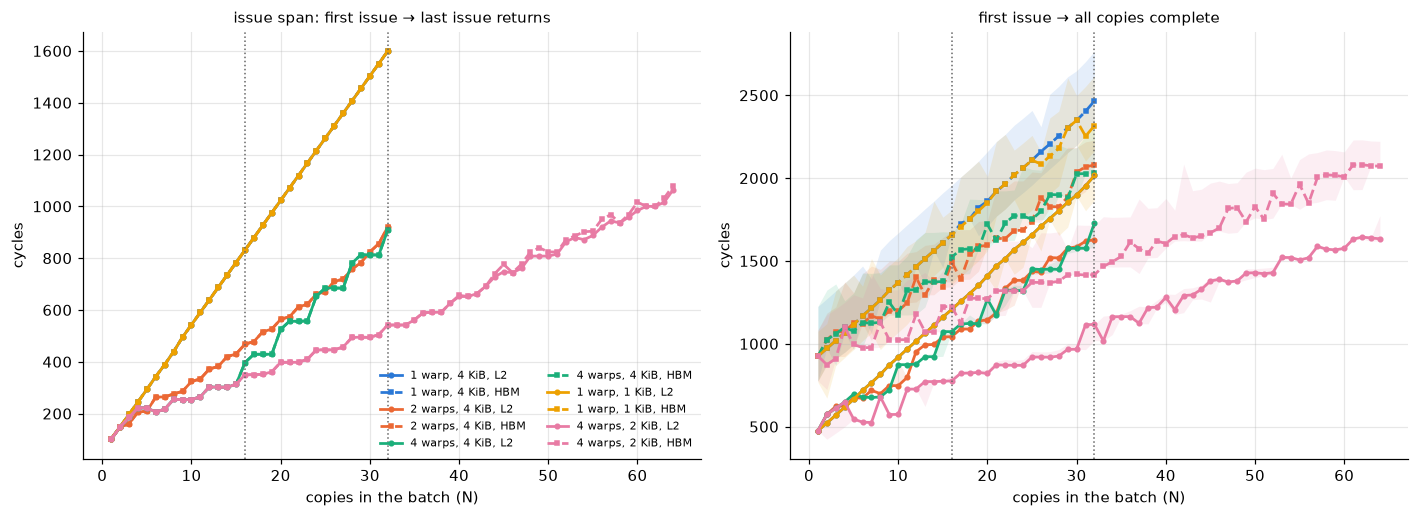

In [10]:
I = iss.copy()
I["per_issue_mean"] = I.issue_span_cycles / I.n_in_flight
def series(issuers, sms, size, src, col):
    d = I[(I.issuers == issuers) & (I.sms == sms) & (I.copy_bytes == size) & (I.source == src)]
    g = d.groupby("n_in_flight")[col]
    return g.median(), g.quantile(.05), g.quantile(.95)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
cfgs = [(1, 1, 4096, "1 warp, 4 KiB"), (2, 1, 4096, "2 warps, 4 KiB"), (4, 1, 4096, "4 warps, 4 KiB"),
        (1, 1, 1024, "1 warp, 1 KiB"), (4, 1, 2048, "4 warps, 2 KiB")]
for j, (w, s, z, lab) in enumerate(cfgs):
    for src, ls, mk in [("l2", "-", "o"), ("hbm", "--", "s")]:
        m, a, b = series(w, s, z, src, "issue_span_cycles")
        if len(m) == 0: continue
        axs[0].plot(m.index, m.values, color=C[j], ls=ls, marker=mk, ms=3, label=f"{lab}, {src.upper()}")
        m, a, b = series(w, s, z, src, "completion_cycles")
        axs[1].fill_between(m.index, a, b, color=C[j], alpha=0.12, lw=0)
        axs[1].plot(m.index, m.values, color=C[j], ls=ls, marker=mk, ms=3, label=f"{lab}, {src.upper()}")
for ax, t in zip(axs, ["issue span: first issue → last issue returns", "first issue → all copies complete"]):
    ax.axvline(16, color="0.4", ls=":", lw=1); ax.axvline(32, color="0.4", ls=":", lw=1)
    ax.set_xlabel("copies in the batch (N)"); ax.set_ylabel("cycles"); ax.set_title(t, fontsize=10)
axs[0].legend(fontsize=7, ncol=2); fig.tight_layout(); plt.show()

- **One warp.** A single warp issues one copy every **48 cycles**, independent of copy size (1 or 4 KiB), source (L2 or HBM) and N: the issue span is 103 + 48 (N − 1) cycles. One warp therefore moves at most 4096 B / 48 = 85 B/cycle in 4-KiB copies.
- **The first copy of a warp** is handed over ≈ 100 cycles after the warp's start timestamp, against 48 for each later one. Before its first copy instruction, the warp computes the copy addresses and moves them into the uniform registers the TMA instruction reads (≈ 20 instructions), which adds ≈ 55 cycles once.
- **Several warps** on different sub-partitions start together and do this preparation in parallel. But their first commands are accepted one after another, ≈ 37 cycles apart (table below): four copies from four warps take 222 cycles, against 245 from one warp. Parallel issue pays off over longer batches, at an aggregate ≈ 22 cycles per copy with two warps and 13–14 with four, i.e. the unit accepts a command every ≈ 13 cycles (≈ 3.5 times one warp's rate).
- **The data-rate knee.** With four warps and 4-KiB copies the issue slope bends at N ≈ 16 to **≈ 32 cycles per copy = 4096 B / 128 B per cycle**. With 2-KiB copies the steady gap is 16 cycles = 2048 / 128. The bend is identical for L2 and HBM sources, so it is set by the unit's own processing rate (128 B/cycle) and not by outstanding memory requests. Below the bend the queue in front of the unit absorbs the burst.
- **Completion** of the whole batch is (issue span) + one copy's latency.

**Start of a batch.** Median hand-over time (cycles after the earliest warp's start timestamp) of the first copies, for 4-KiB copies from L2; copy *i* is issued by warp *i* mod W.

In [11]:
st = {}
for w in [1, 2, 4]:
    for n in [1, 2, 4, 8]:
        d = I[(I.sms == 1) & (I.copy_bytes == 4096) & (I.source == "l2") & (I.issuers == w) & (I.n_in_flight == n)]
        t = np.median(np.array([[int(v) for v in r.split(";")] for r in d.issue_cycles_list.astype(str)]), 0)
        st[f"{w} warp(s), N = {n}"] = {"hand-over times of copies 0, 1, …": ", ".join(f"{x:.0f}" for x in t),
                                       "issue span": d.issue_span_cycles.median()}
display(pd.DataFrame(st).T)

,"hand-over times of copies 0, 1, …",issue span
"1 warp(s), N = 1",103,103.0
"1 warp(s), N = 2","101, 149",149.0
"1 warp(s), N = 4","101, 149, 197, 245",245.0
"1 warp(s), N = 8","103, 151, 199, 247, 295, 343, 391, 439",439.0
"2 warp(s), N = 1",101,101.0
"2 warp(s), N = 2","113, 148",148.0
"2 warp(s), N = 4","113, 148, 161, 206",206.0
"2 warp(s), N = 8","94, 132, 142, 180, 190, 228, 238, 276",276.0
"4 warp(s), N = 1",101,101.0
"4 warp(s), N = 2","113, 148",148.0


**Issue gap and the throughput of a full batch.** Slopes of the median issue span over three ranges of N, and the marginal data rate of the batch between two N.

In [12]:
def gaps(issuers, size, src, nmax):
    d = I[(I.issuers == issuers) & (I.sms == 1) & (I.copy_bytes == size) & (I.source == src)]
    m = d.groupby("n_in_flight").issue_span_cycles.median()
    out = {}
    for lo, hi in [(1, 16), (17, 32), (33, 64)]:
        s = m[(m.index >= lo) & (m.index <= min(hi, nmax))]
        if len(s) > 2: out[f"slope N {lo}–{hi}"] = np.polyfit(s.index, s.values, 1)[0]
    out["span N=1"] = m.get(1, np.nan)
    return out
gt = pd.DataFrame({f"{w} warp(s), {z // 1024} KiB, {src}": gaps(w, z, src, 64 if z == 2048 else 32)
                   for w, z in [(1, 4096), (2, 4096), (4, 4096), (1, 1024), (4, 2048)] for src in ["l2", "hbm"]}).T
display(gt.round(1).rename_axis("issue span (cycles); slope = cycles per additional copy"))
# completion throughput at the largest batches: bytes / (completion(N_hi) − completion(N_lo))
def drain(issuers, size, src, lo, hi):
    d = I[(I.issuers == issuers) & (I.sms == 1) & (I.copy_bytes == size) & (I.source == src)]
    m = d.groupby("n_in_flight").completion_cycles.median()
    return (hi - lo) * size / (m[hi] - m[lo])
print("bytes per cycle between the completion of N_lo and N_hi copies (marginal rate of the batch):")
for w, z, lo, hi in [(1, 4096, 16, 32), (2, 4096, 16, 32), (4, 4096, 16, 32), (4, 2048, 32, 64)]:
    print(f"  {w} warp(s), {z} B, N {lo}→{hi}: L2 {drain(w, z, 'l2', lo, hi):.1f}, HBM {drain(w, z, 'hbm', lo, hi):.1f} B/cycle")

,slope N 1–16,slope N 17–32,span N=1,slope N 33–64
issue span (cycles); slope = cycles per additional copy,,,,
"1 warp(s), 4 KiB, l2",48.9,48.0,103.0,NaN
"1 warp(s), 4 KiB, hbm",48.9,48.0,103.0,NaN
"2 warp(s), 4 KiB, l2",22.5,27.0,101.0,NaN
"2 warp(s), 4 KiB, hbm",22.5,27.0,101.0,NaN
"4 warp(s), 4 KiB, l2",14.1,31.8,101.0,NaN
"4 warp(s), 4 KiB, hbm",14.1,31.8,101.0,NaN
"1 warp(s), 1 KiB, l2",48.9,48.0,103.0,NaN
"1 warp(s), 1 KiB, hbm",48.9,48.0,103.0,NaN
"4 warp(s), 2 KiB, l2",13.0,12.2,101.0,16.7


bytes per cycle between the completion of N_lo and N_hi copies (marginal rate of the batch):
  1 warp(s), 4096 B, N 16→32: L2 81.0, HBM 81.0 B/cycle
  2 warp(s), 4096 B, N 16→32: L2 112.0, HBM 112.0 B/cycle
  4 warp(s), 4096 B, N 16→32: L2 99.8, HBM 129.3 B/cycle
  4 warp(s), 2048 B, N 32→64: L2 126.9, HBM 100.1 B/cycle


**Figure 3b.** Gap between consecutive issue returns inside one batch (median over samples), for one warp issuing 32 × 4 KiB and four warps issuing 64 × 2 KiB.

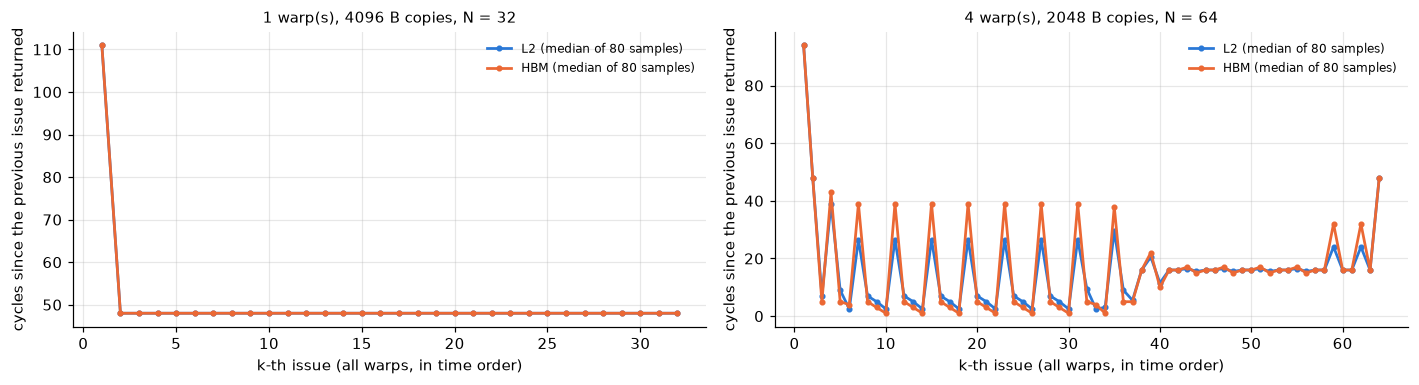

,single-copy completion (cycles),copies outstanding at once ≥ (median),min over samples
"1 warp(s), 4096 B, N = 32, L2",475.0,6.0,6.0
"1 warp(s), 4096 B, N = 32, HBM",925.0,15.0,15.0
"2 warp(s), 4096 B, N = 32, L2",474.0,11.0,11.0
"2 warp(s), 4096 B, N = 32, HBM",924.0,29.0,29.0
"4 warp(s), 4096 B, N = 32, L2",476.0,18.0,18.0
"4 warp(s), 4096 B, N = 32, HBM",926.0,31.0,31.0
"1 warp(s), 1024 B, N = 32, L2",475.0,6.0,6.0
"1 warp(s), 1024 B, N = 32, HBM",925.0,15.0,15.0
"4 warp(s), 2048 B, N = 64, L2",476.0,18.5,18.0
"4 warp(s), 2048 B, N = 64, HBM",926.0,52.0,52.0


In [13]:
def gaps_of(row):
    t = np.array([int(v) for v in str(row.issue_cycles_list).split(";")])
    return np.diff(np.concatenate([[0], np.sort(t)]))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (w, z, n) in zip(axs, [(1, 4096, 32), (4, 2048, 64)]):
    for j, src in enumerate(["l2", "hbm"]):
        d = I[(I.issuers == w) & (I.sms == 1) & (I.copy_bytes == z) & (I.source == src) & (I.n_in_flight == n)]
        G = np.vstack([gaps_of(r) for r in d.itertuples()])
        ax.plot(np.arange(1, n + 1), np.median(G, 0), color=C[j], marker="o", ms=3, label=f"{src.upper()} (median of {len(G)} samples)")
    ax.set_xlabel("k-th issue (all warps, in time order)"); ax.set_ylabel("cycles since the previous issue returned")
    ax.set_title(f"{w} warp(s), {z} B copies, N = {n}", fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

# lower bound on copies outstanding at once: copies issued before the first copy of the batch can have completed
# (first issue + the median completion time of a batch of one, minus 100 cycles of margin)
rows = {}
for w, z, n in [(1, 4096, 32), (2, 4096, 32), (4, 4096, 32), (1, 1024, 32), (4, 2048, 64)]:
    for src in ["l2", "hbm"]:
        d = I[(I.issuers == w) & (I.sms == 1) & (I.copy_bytes == z) & (I.source == src)]
        lat1 = d[d.n_in_flight == 1].completion_cycles.median()
        big = d[d.n_in_flight == n]
        lb = [(np.sort([int(v) for v in r.split(";")]) < lat1 - 100).sum() for r in big.issue_cycles_list]
        rows[f"{w} warp(s), {z} B, N = {n}, {src.upper()}"] = {"single-copy completion (cycles)": lat1,
                                                              "copies outstanding at once ≥ (median)": np.median(lb), "min over samples": np.min(lb)}
display(pd.DataFrame(rows).T)

- **Issue timeline.** A single warp's copies leave at exactly 48-cycle intervals. Four warps issue in bursts: the four warps' commands arrive within a few cycles, followed by ≈ 39-cycle pauses. After ≈ 38 copies the issue settles at the drain rate.
- **No admission limit at 16 in flight.** The table counts the copies issued before the first copy of the batch can possibly have completed, using a batch of one copy minus 100 cycles. All of these are outstanding at the same time. With HBM sources, 4 warps had **≥ 52 copies (104 KiB)** in flight, and even a single warp ≥ 15. The issue of the 17th copy shows no step in any configuration (Figure 3b).

**Several SMs at once.** The same batches issued by 1, 2, 4 or 8 SMs simultaneously (medians; one row per source and N).

In [14]:
M = I[(I.issuers == 1) & (I.copy_bytes == 4096)]
mt = M[M.n_in_flight.isin([1, 8, 16, 32])].groupby(["source", "n_in_flight", "sms"])[["issue_span_cycles", "completion_cycles"]].median().unstack("sms")
display(mt.round(0).astype(int))
sk = M[M.sms > 1].groupby("sms").start_skew_ns.quantile([.5, .95]).unstack().rename(columns={.5: "median", .95: "p95"})
print("start skew between the blocks of one sample (ns):"); display(sk)
print("SMs used per sms value:", {s: sorted(M[M.sms == s].smid.unique())[:8] for s in sorted(M.sms.unique())})

issue_span_cycles                   completion_cycles                  
sms                                1     2     4     8                 1     2     4     8
source n_in_flight                                                                        
hbm    1                         103   103   103   103               925   925   925   925
       8                         439   439   439   439              1265  1265  1265  1266
       16                        831   831   831   831              1657  1657  1657  1657
       32                       1599  1599  1599  1599              2466  2466  2466  2466
l2     1                         103   103   103   103               475   475   475   475
       8                         439   439   439   439               815   815   815   815
       16                        831   831   831   831              1207  1207  1207  1207
       32                       1599  1599  1599  1599              2016  2016  2016  2016

start skew between the blocks of one sample (ns):


,median,p95
sms,,
2,0.0,32.0
4,0.0,32.0
8,0.0,32.0


SMs used per sms value: {np.int64(1): [np.int64(124)], np.int64(2): [np.int64(124), np.int64(126)], np.int64(4): [np.int64(124), np.int64(126), np.int64(128), np.int64(130)], np.int64(8): [np.int64(124), np.int64(125), np.int64(126), np.int64(127), np.int64(128), np.int64(129), np.int64(130), np.int64(131)]}


Up to 8 SMs issuing at the same instant see exactly the same issue spans and completion times as one SM; the start skew is at most one 32-ns `%globaltimer` tick. The scheduler placed these blocks on SMs 124–131 (pairs of SMs sharing a TPC, in GPCs 0, 4 and 5), so even two TPC mates do not share any TMA resource at this load.

### 4. Tensor-map loads: box shape, swizzle, descriptor state (K4)

**Figure 4.** Issue → completion of one 16-KiB tensor load with a warm descriptor, per box shape and swizzle mode, for warm-L2 and cold (HBM) data (median, p5–p95). The first table gives the medians, the second the shared-memory span each mode writes.

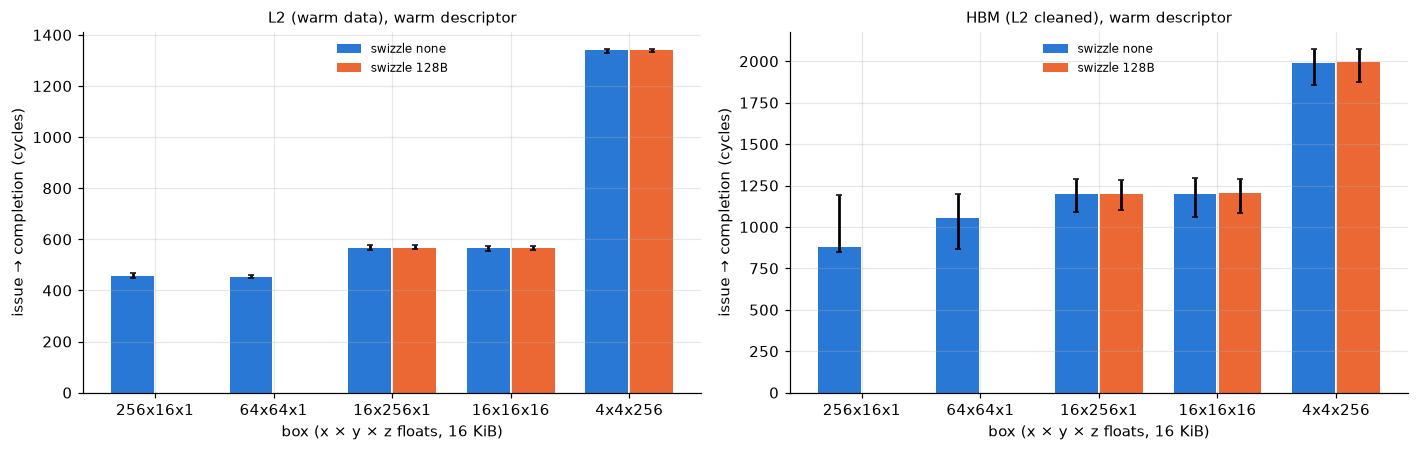

source       hbm              l2        
swizzle     128B    none    128B    none
box                                     
256x16x1     NaN   880.0     NaN   457.0
64x64x1      NaN  1052.0     NaN   454.0
16x256x1  1199.0  1200.0   568.0   565.0
16x16x16  1205.0  1200.0   568.0   565.0
4x4x256   1994.0  1992.0  1340.0  1339.0

smem span written (B)  smem bytes changed
box      swizzle                                           
256x16x1 none                     16384               16384
64x64x1  none                     16384               16384
16x256x1 128B                     32768               16384
         none                     16384               16384
16x16x16 128B                     32768               16384
         none                     16384               16384
4x4x256  128B                    131072               16384
         none                     16384               16384

,row bytes,rows per box,L2 measured,"L2 model: 329 + max(rows, bytes/128)",HBM measured,"HBM model: 752 + max(rows, bytes/128)"
256x16x1,1024,16,457.0,457.0,880.0,880.0
64x64x1,256,64,454.0,457.0,1052.0,880.0
16x256x1,64,256,565.0,585.0,1200.0,1008.0
16x16x16,64,256,565.0,585.0,1200.0,1008.0
4x4x256,16,1024,1339.0,1353.0,1992.0,1776.0


In [15]:
B = bx[bx.encode_ok == 1]
order = ["256x16x1", "64x64x1", "16x256x1", "16x16x16", "4x4x256"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
for ax, src in zip(axs, ["l2", "hbm"]):
    d = B[(B.source == src) & (B.descriptor_state == "warm")]
    for k, sw in enumerate(["none", "128B"]):
        g = d[d.swizzle == sw].groupby("box").cycles
        m = g.median().reindex(order); a = g.quantile(.05).reindex(order); b = g.quantile(.95).reindex(order)
        xs = np.arange(len(order)) + (k - 0.5) * 0.38
        ax.bar(xs, m.values, width=0.36, color=C[k], yerr=[m - a, b - m], capsize=2, label=f"swizzle {sw}")
    ax.set_xticks(np.arange(len(order)), order); ax.set_xlabel("box (x × y × z floats, 16 KiB)")
    ax.set_ylabel("issue → completion (cycles)"); ax.set_title(f"{'L2 (warm data)' if src == 'l2' else 'HBM (L2 cleaned)'}, warm descriptor", fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
w = B[B.descriptor_state == "warm"].groupby(["source", "swizzle", "box"]).cycles.median().unstack(["source", "swizzle"]).reindex(order)
display(w.round(0))
ext = B.groupby(["box", "swizzle"])[["smem_extent_bytes", "smem_written_bytes"]].max().reindex(order, level=0)
display(ext.astype(int).rename(columns={"smem_extent_bytes": "smem span written (B)", "smem_written_bytes": "smem bytes changed"}))

rowsz = {b: int(b.split("x")[0]) * 4 for b in order}
nrows = pd.Series({b: 16384 // rowsz[b] for b in order})
work = np.maximum(nrows, 16384 / 128)  # cycles if the unit moves one box row or 128 B per cycle, whichever is slower
tab = pd.DataFrame({"row bytes": rowsz, "rows per box": nrows})
for src in ["l2", "hbm"]:
    w_ = B[(B.source == src) & (B.descriptor_state == "warm") & (B.swizzle == "none")].groupby("box").cycles.median().reindex(order)
    fixed = (w_ - work).loc["256x16x1"]
    tab[f"{src.upper()} measured"] = w_
    tab[f"{src.upper()} model: {fixed:.0f} + max(rows, bytes/128)"] = fixed + work
display(tab.round(0))

- **Box shape is governed by the number of box rows.** A row is the run along the innermost dimension.
  - Boxes whose rows are ≥ 256 B (256×16×1, 64×64×1) complete in ≈ 455 cycles from L2: the 128 B/cycle data rate.
  - With 64-B rows (16×256×1, 16×16×16, 256 rows) the load takes ≈ 565 cycles.
  - With 16-B rows (4×4×256, 1024 rows) it takes ≈ 1340 cycles.

  The model *fixed + max(rows, bytes / 128)* reproduces the five L2 values within ≈ 20 cycles: **the unit handles at most one box row per cycle**, so rows narrower than 128 B waste data bandwidth. Whether the extent of the other dimensions lies in y or z makes no difference.
- **HBM.** From HBM, the 64×64×1 box is ≈ 170 cycles slower than 256×16×1 although both need the same 128 cycles of transfer. Its 64 rows lie 4 KiB apart, against 16 rows for the wider box.
- **Swizzle.** The 128-B swizzle costs no time. But in shared memory **each box row then occupies a full 128-B row**: a box with 64-B rows spans 32 KiB and one with 16-B rows 128 KiB for 16 KiB of data (the scan shows only 16 KiB actually written). The destination must be sized for that span. This experiment measures the load side only. The benefit of swizzling, fewer bank conflicts when the tile is read from shared memory, and the 32B/64B modes are not measured here.

**Descriptor state.** Per box and swizzle, the median of each state minus the warm median (summary over the 8 box/swizzle combinations):
- cold: the first use of a tensor map in the launch;
- cold_late: a fourth map whose first use comes at the end of the launch;
- prefetched: `prefetch.tensormap`, then 5 µs, then the first use.

Below: HBM-source medians by the barrier parity waited on.

In [16]:
D = B.groupby(["source", "box", "swizzle", "descriptor_state"]).cycles.median().unstack()
DD = pd.DataFrame({"cold − warm": D.cold - D.warm, "cold_late − warm": D.cold_late - D.warm, "prefetched − warm": D.prefetched - D.warm})
display(DD.groupby("source").describe().T.loc[pd.IndexSlice[:, ["min", "50%", "max"]], :].round(1))
par = B[B.source == "hbm"].groupby(["descriptor_state", "parity"]).cycles.median().unstack()
print("HBM source, median cycles by the mbarrier parity waited on (all boxes):"); display(par.round(0))

source                  hbm    l2
cold − warm       min  28.0  34.5
                  50%  41.8  35.2
                  max  63.0  37.0
cold_late − warm  min -49.5  32.0
                  50%  39.5  34.5
                  max  65.5  36.0
prefetched − warm min -28.0  -6.5
                  50%   1.5  -5.0
                  max  53.0  -5.0

HBM source, median cycles by the mbarrier parity waited on (all boxes):


parity,0,1
descriptor_state,,
cold,1244.0,1254.0
cold_late,1246.0,1240.0
prefetched,1230.0,1205.0
warm,1206.0,1199.0


- **The first use of a tensor map in a launch costs ≈ 35 cycles extra** (32–37 over all boxes, L2 source). This holds whether that first use comes at the start or at the end of the launch, so the descriptor is not cached across the launch boundary or from neighbouring parameters.
- **`prefetch.tensormap`** issued 5 µs before the first use removes the penalty completely.
- **HBM.** With HBM data the same differences are within the HBM spread. The barrier parity has no systematic effect.

### 5. Hardware counters and SASS

Nsight Compute counters of the profiled kernels (application replay, our clock lock, warm caches). Per-hop values divide by the 65 536 hops of each profiled chase.

In [17]:
cols = {"variant": "kernel config", "footprint_bytes": "footprint B", "sm__sass_inst_executed_op_tma_ld.sum": "TMA ld instr",
        "l1tex__tmain_requests.sum": "TMA requests", "l1tex__m_xbar2l1tex_read_bytes_mem_global_op_tma_ld.sum": "TMA bytes from L2",
        "sm__pipe_tma_cycles_active.max": "TMA pipe active cycles (SM max)", "lts__t_sectors_srcunit_tex_op_read.sum": "L2 read sectors (tex)",
        "lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum": "L2 read misses", "l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum": "LSU global ld sectors",
        "l1tex__m_xbar2l1tex_read_bytes_mem_global_op_tma_ld.avg.peak_sustained": "rated TMA read B/cycle (peak_sustained)",
        "hops": "hops / samples"}
n1 = nch[[c for c in cols if c in nch.columns]].rename(columns=cols)
n1["TMA bytes per hop"] = n1["TMA bytes from L2"].astype(float) / n1["hops / samples"]
n1["L2 sectors per hop"] = n1["L2 read sectors (tex)"].astype(float) / n1["hops / samples"]
display(n1.set_index(["kernel config", "footprint B"]))
n2 = nco.assign(config=lambda d: "K2 one copy of " + d.payload_bytes.astype(str) + " B × 96")
n3 = nis.assign(config=lambda d: "K3 batch of " + d.n_in_flight.astype(str) + " × 4 KiB × 16")
keep = ["config", "sm__sass_inst_executed_op_tma_ld.sum", "l1tex__m_xbar2l1tex_read_bytes_mem_global_op_tma_ld.sum",
        "sm__pipe_tma_cycles_active.max", "l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum"]
display(pd.concat([n2[keep], n3[keep]]).rename(columns=cols).set_index("config"))

,,TMA ld instr,TMA requests,TMA bytes from L2,TMA pipe active cycles (SM max),L2 read sectors (tex),L2 read misses,LSU global ld sectors,rated TMA read B/cycle (peak_sustained),hops / samples,TMA bytes per hop,L2 sectors per hop
kernel config,footprint B,,,,,,,,,,,
bulk16,8388608,65536,65536,2097152,131072,65536,0,0,128,65536,32.0,1.0
tensor2d,8388608,65536,65536,8388608,131072,262144,0,0,128,65536,128.0,4.0
ld_cg,8388608,0,0,0,0,65536,0,65536,128,65536,0.0,1.0
cp_async16,8388608,0,0,0,0,65536,0,65536,128,65536,0.0,1.0
bulk16,268435456,65536,65536,2097152,131072,65536,131072,0,128,65536,32.0,1.0


,TMA ld instr,TMA bytes from L2,TMA pipe active cycles (SM max),LSU global ld sectors
config,,,,
K2 one copy of 65536 B × 96,96,6291456,192,0
K2 one copy of 4096 B × 96,96,4325376,192,0
K3 batch of 16 × 4 KiB × 16,1280,5242880,2560,1
K3 batch of 32 × 4 KiB × 16,1536,6291456,3072,1


In [18]:
import re
sass = open("results/sass/tma_chase.sass").read()
fn = sass[sass.index("Function : _Z8k1_chaseILi0E"):]
fn = fn[: fn.index("Function :", 20)] if "Function :" in fn[20:] else fn
lines = [re.sub(r"\s*/\*[0-9a-f]{4}\*/\s*", "", l).split(";")[0].strip() for l in fn.splitlines() if re.match(r"\s+/\*[0-9a-f]{4}\*/", l)]
t0 = next(i for i, l in enumerate(lines) if "SR_CLOCKLO" in l)              # start of the timed region
a0 = next(i for i in range(t0, len(lines)) if "SYNCS.ARRIVE.TRANS64" in lines[i])
a1 = next(i for i in range(a0 + 1, len(lines)) if "SYNCS.ARRIVE.TRANS64" in lines[i])
u1 = next(i for i in range(a1, len(lines)) if "UBLKCP" in lines[i])
print("one hop of the bulk16 chase inside the timed loop, up to the next issue (SASS; the wait's retry path is out of line):")
print("\n".join("    " + l for l in lines[a0: u1 + 1]))

one hop of the bulk16 chase inside the timed loop, up to the next issue (SASS; the wait's retry path is out of line):
    SYNCS.ARRIVE.TRANS64 RZ, [UR5], R2
    @P0 ELECT P1, URZ, PT
    UMOV UR9, UR5
    UBLKCP.S.G [UR8], [UR14], UR7
    @P1 PLOP3.LUT P0, PT, P1, PT, PT, 0x8, 0x0
    PLOP3.LUT P1, PT, PT, PT, PT, 0x8, 0x0
    @P0 BRA.U.ANY 0x1190
    SYNCS.PHASECHK.TRANS64.TRYWAIT P0, [UR5], RZ
    @!P0 BRA 0x23e0
    LDS.64 R8, [UR8]
    SYNCS.ARRIVE.TRANS64 RZ, [UR5], R2
    IADD3 R0, P0, R0, 0x1, RZ
    UMOV UR7, 0x1
    ISETP.GE.U32.AND P1, PT, R0, UR6, PT
    IMAD.X R4, RZ, RZ, R4, P0
    PLOP3.LUT P0, PT, PT, PT, PT, 0x80, 0x0
    ISETP.GE.U32.AND.EX P1, PT, R4, UR4, PT, P1
    R2UR UR10, R8
    R2UR UR11, R9
    @P0 ELECT P2, URZ, PT
    UMOV UR9, UR5
    UBLKCP.S.G [UR8], [UR10], UR7


- **Every TMA chase executes exactly one TMA instruction per hop and no LSU global load.** The async path never touches the LSU or L1.
- **Sector requests per hop:**
  - a 16-B bulk copy requests one 32-B sector from L2;
  - the 2-D box with four 16-B rows requests four sectors (128 B for 64 B of payload): every row is a separate request.
- **Pipe time.** The TMA pipe is active for 2 cycles per command.
- **Rated peak.** The read path is rated at 128 B/cycle per SM (`peak_sustained`), the rate the issue throttles to in K3.
- **HBM misses.** The 256 MiB chase misses in L2 on every hop, with exactly 2 L2 lookups per hop: a miss is looked up twice, as for generic loads.

## Insights

1. **The async load path is not slower than the LSU path; observing it is what costs.**
   - A dependent 16-B TMA load costs ≈ 52 cycles more than `ld.global.cg` from L2 and from HBM alike, ≈ 67 for tensor-map loads.
   - The wait instruction (≈ 30 cycles) plus the shared-memory read of the result (≈ 23) and the `arrive.expect_tx` account for all of it.
   - The TMA's own L2 round trip, ≈ 260 cycles by this decomposition (an estimate), is no longer than an LSU load.
   - The TMA never uses L1, so for data that would hit in L1 the async path is ≈ 10× slower.
2. **A copy has a fixed latency of ≈ 330–340 cycles, then streams at ≈ 107 B/cycle per SM.**
   - Payloads up to 1 KiB cost the same as 16 B.
   - Batches from several warps reach 100–130 B/cycle, the 128 B/cycle rated read peak of the unit: about 4 sectors per cycle, 210 GB/s per SM at 1635 MHz.
   - Small copies are therefore latency-bound; ≥ 4 KiB copies are needed to approach the per-SM rate.
3. **Issue is a per-warp cost.**
   - One warp issues a copy every 48 cycles (85 B/cycle with 4-KiB copies, 21 B/cycle with 1-KiB copies).
   - Copies from 2–4 warps on different sub-partitions are accepted every ≈ 13 cycles once a batch is under way; the first commands of different warps are accepted ≈ 37 cycles apart, and each warp's first copy carries ≈ 55 cycles of address preparation.
   - Beyond the queue in front of the unit, issue throttles to the 128 B/cycle processing rate.
   - There is **no admission limit at 16 transactions**: ≥ 52 copies were outstanding at once from HBM without any issue stall.
   - The TMA units of different SMs (also TPC mates) are independent.
4. **Wait instruction choice.**
   - A `try_wait.parity` loop observes completion fastest at L2 latency and needs one call.
   - `test_wait` quantises observation to its ≈ 50-cycle loop (+18 cycles per hop on average).
   - The suspend hint makes the successful call cost ≈ 60 instead of 30 cycles, and does not shorten the ≈ 4.8 µs after which an unsatisfied `try_wait` returns false.
   - For long (HBM) waits, the hint forms and `test_wait` were intermittently ≈ 45 cycles per hop faster than the plain `try_wait`, in a state that persisted over consecutive launches. This is unexplained by the measurements here.
5. **Tensor maps.**
   - Descriptor handling adds ≈ 15 cycles per load and ≈ 35 cycles on a map's first use in a launch; `prefetch.tensormap` removes the latter.
   - Box cost follows max(rows, bytes/128) cycles: boxes should have rows of ≥ 128 B.
   - 128-B swizzle is free in time but pads every row to 128 B in shared memory.
6. **Software prefetch into L2 works for pointer-like access.** Issuing `cp.async.bulk.prefetch.L2` one hop ahead cuts an HBM-bound chase by ≈ 24 %. The L2 eviction hint has no effect at single-SM scale.

**Limitations.**
- All latencies are measured from one thread on one SM: SM 2 and SM 8 for K1, SM 2 for K2, and whichever SM the scheduler chose for K3/K4 (SMs 124–131). Per-SM differences in K1 were ≤ 5 cycles.
- HBM-sourced single copies vary by ±200 cycles with the line's memory location, so their medians carry ≈ ±20 cycles of sampling noise.
- The queue depth in front of the TMA unit cannot be read directly from issue times; only the throttling to 128 B/cycle is observable.